# Random Forest: Restaurante(<20)

**Integrante:** [nombre]. **Laboratorio 3 — Ruta Alpes.**

Seguimos la estructura de la [práctica del curso](../MaterialDeClase-ISIS-2611/202620/Prácticas/P10_Ensembles/P10_RandomForest.ipynb).
La limpieza se documenta en el notebook compartido. Este archivo parte del CSV preparado por el equipo.
Plantilla sin ejecutar: completar las decisiones y los análisis pendientes con evidencia propia.

**Pregunta inicial:** ¿qué características del conductor y del trayecto ayudan a predecir la aceptación de este cupón?


## 1. Importación de librerías


In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)


In [2]:
from sklearn.ensemble import RandomForestClassifier


## 2. Carga de los datos

Ejecutar desde la raíz de LABORATORIO-3-AM. El CSV debe conservar id_fila, cupon y acepta_cupon en Sí/No.
Puede contener faltantes en predictores: se imputan dentro del pipeline. Los faltantes de la etiqueta no se imputan.


In [3]:
CUPON = 'Restaurante(<20)'
ALGORITMO = 'bosque_aleatorio'
SEMILLA = 42
N_FOLDS = 5
N_JOBS = -1
RUTA_DATOS = Path('data/procesados/datos_limpios.csv')
RUTA_RESULTADOS = Path('resultados') / 'restaurante_bosque_aleatorio'
# Completar con las decisiones de la limpieza; mantenerlas entre algoritmos.
# vehiculo, tiempo_cupon_mayor_5min y direccion_opuesta
# ya se eliminaron en el notebook de limpieza compartido.
COLUMNAS_EXCLUIR = []
COLUMNAS_NUMERICAS = ['temperatura']

if not RUTA_DATOS.exists():
    raise FileNotFoundError('Falta data/procesados/datos_limpios.csv. Preparar el CSV y abrir desde la raíz del laboratorio.')
datos = pd.read_csv(RUTA_DATOS)


In [4]:
requeridas = {'id_fila', 'cupon', 'acepta_cupon'}
if not requeridas.issubset(datos.columns):
    raise ValueError(f'Faltan columnas: {requeridas - set(datos.columns)}')
if datos['id_fila'].isna().any() or not datos['id_fila'].is_unique:
    raise ValueError('id_fila debe ser único y no tener faltantes.')
data = datos.loc[datos['cupon'].eq(CUPON)].copy()
data = data.sort_values('id_fila').set_index('id_fila')
if data.empty:
    raise ValueError(f'No se encontraron filas de {CUPON}. Revisar las categorías del CSV.')
if data['acepta_cupon'].isna().any() or not set(data['acepta_cupon']).issubset({'Sí', 'No'}):
    raise ValueError('acepta_cupon debe contener solamente Sí y No, sin faltantes.')
data.head()


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,acepta_cupon
id_fila,,,,,,,,,,,,,,,,,,,,,
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,Sí
5,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí
7,Sin lugar urgente,Hijo(s),Soleado,80,10:00 a.m.,Restaurante(<20),2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí
10,Sin lugar urgente,Hijo(s),Soleado,80,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,Sí
11,Sin lugar urgente,Hijo(s),Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí


## 3. Revisión del subconjunto

La exploración completa y las correcciones pertenecen al notebook de limpieza. Aquí comprobamos qué datos llegan al modelo.


In [5]:
data.shape


(2769, 23)

In [6]:
data.isna().sum()


destino                             0
acompanante                         0
clima                               0
temperatura                         0
hora                                0
cupon                               0
vigencia_cupon                      0
genero                              0
edad                                0
estado_civil                        0
tiene_hijos                         0
educacion                           0
ocupacion                           0
ingreso                             0
frecuencia_bar                     23
frecuencia_cafeteria               47
frecuencia_comida_para_llevar      34
frecuencia_restaurante_menos_20    27
frecuencia_restaurante_20_a_50     43
tiempo_cupon_mayor_15min            0
tiempo_cupon_mayor_25min            0
misma_direccion                     0
acepta_cupon                        0
dtype: int64

In [7]:
data['acepta_cupon'].value_counts()


Sí    1959
No     810
Name: acepta_cupon, dtype: int64

**Por completar:** resumir la distribución de clases, las columnas descartadas y las decisiones de limpieza relevantes para este cupón. No suponer que el balanceo mejorará el resultado antes de medirlo.


## 4. Partición de los datos

Sí se representa con 1 y No con 0. Excluimos cupon, que es constante, y la etiqueta de los predictores. id_fila quedó como índice.
La semilla, la fracción de test y los folds deben ser iguales para los tres modelos del mismo cupón.


In [8]:
X = data.drop(columns=['acepta_cupon', 'cupon', *COLUMNAS_EXCLUIR])
y = data['acepta_cupon'].map({'No': 0, 'Sí': 1}).astype(int)
numericas_features = [c for c in COLUMNAS_NUMERICAS if c in X.columns]
categoricas_features = [c for c in X.columns if c not in numericas_features]

# Conservamos los faltantes como np.nan para SimpleImputer.
# Edad, ingreso y frecuencias son categorías según el diccionario.
for columna in categoricas_features:
    X[columna] = X[columna].astype('string').astype(object)
    X[columna] = X[columna].where(X[columna].notna(), np.nan)
for columna in numericas_features:
    X[columna] = pd.to_numeric(X[columna], errors='raise')
    if not np.isfinite(X[columna].dropna().to_numpy()).all():
        raise ValueError(f'Hay valores no finitos en {columna}. Revisar la limpieza.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)
if y_train.nunique() != 2 or y_train.value_counts().min() < N_FOLDS:
    raise ValueError('Se requieren ambas clases y suficientes ejemplos para cinco folds.')
if numericas_features and X_train[numericas_features].isna().all().any():
    raise ValueError('Hay columnas numéricas completamente vacías en train. Revisar si deben excluirse.')
clase_minoritaria = int(y_train.value_counts().idxmin())
kfold = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Clase minoritaria en train:', {0: 'No', 1: 'Sí'}[clase_minoritaria])


Train: (2215, 21) | Test: (554, 21)
Clase minoritaria en train: No


## 5. Construccion del pipeline

Seguimos el esquema de SimpleImputer y ColumnTransformer de la practica 7. 
La mediana numerica y la moda de cada variable categorica se calculan dentro de cada fold de entrenamiento.


Aunque los árboles no necesitan escalamiento, lo mantenemos en las dos variantes de Restaurante porque SMOTE calcula distancias. Así el experimento solo cambia el muestreo.


In [9]:
numerica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])


Codificamos las categorías con OneHotEncoder(handle_unknown='ignore'), como en la práctica de árboles.


In [10]:
categorica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])


In [11]:
preprocesador = ColumnTransformer(transformers=[
    ('num', numerica_transformer, numericas_features),
    ('cat', categorica_transformer, categoricas_features),
])


In [12]:
rf_pipeline = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', RandomForestClassifier(random_state=SEMILLA, n_jobs=1)),
])


## 6. Búsqueda de hiperparámetros

Usamos GridSearchCV de forma explícita, como en las prácticas. Se selecciona por F1 macro en CV, dando igual peso a ambas clases. La práctica 7 usa F1 binario; unificamos F1 macro con las prácticas 8–10 para comparar los tres algoritmos. También reportamos el F1 de aceptación.


Usamos los valores de la grilla de la práctica 10. Allí el bosque recibe datos numéricos sin pipeline; aquí añadimos el preprocesamiento porque hay categorías y el laboratorio exige pipeline. Por eso los parámetros llevan el prefijo modelo__.


In [13]:
param_grid = {
    'modelo__n_estimators': [100, 200, 300],
    'modelo__max_depth': [4, 6, 10],
    'modelo__min_samples_leaf': [1, 3, 5],
}


In [14]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline, param_grid=param_grid,
    cv=kfold, scoring='f1_macro', n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
rf_grid.fit(X_train, y_train)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocesador',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['temperatura']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='most_...
                                                                          'frecuencia_restaurante_menos_20',
                                                                          'frecuencia_restaurante_20_a_50',
                                                                          'tiempo_cupon_mayor_15min',
                                                                          'tiempo_cupon_mayor_25min',
                                                                          'misma_direccion'])])),
                                       ('modelo',
                                        RandomForestClassifier(n_jobs=1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'modelo__max_depth': [4, 6, 10],
                         'modelo__min_samples_leaf': [1, 3, 5],
                         'modelo__n_estimators': [100, 200, 300]},
             return_train_score=True, scoring='f1_macro')

In [15]:
print('Mejores hiperparámetros:', rf_grid.best_params_)
print('F1 macro promedio en CV:', rf_grid.best_score_)
resultados_cv = pd.DataFrame(rf_grid.cv_results_)
columnas_cv = [c for c in resultados_cv.columns if c.startswith('param_')]
columnas_cv += ['mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(resultados_cv[columnas_cv].sort_values('rank_test_score').head(10))
mejor_modelo = rf_grid.best_estimator_
variante_elegida = 'sin_balanceo'


Mejores hiperparámetros: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}
F1 macro promedio en CV: 0.6683118436544364


,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
20,10,1,300,0.829508,0.668312,0.017527,1
18,10,1,100,0.828082,0.667840,0.014621,2
19,10,1,200,0.825821,0.665866,0.017006,3
23,10,3,300,0.743348,0.656823,0.012587,4
22,10,3,200,0.742720,0.654477,0.014936,5
21,10,3,100,0.744649,0.653985,0.019048,6
24,10,5,100,0.704989,0.651047,0.011840,7
26,10,5,300,0.704114,0.651044,0.012886,8
25,10,5,200,0.702921,0.649210,0.011096,9
16,6,5,200,0.654800,0.635746,0.006961,10


**Por completar:** explicar los hiperparámetros ganadores, comparar train con validación y revisar la dispersión entre folds. Si aparecen advertencias de convergencia, resolverlas antes de reportar el resultado.


## 7. Comparación con SMOTE

Adaptamos el esquema ImbPipeline → SMOTE → modelo de la [práctica 9](../MaterialDeClase-ISIS-2611/202620/Prácticas/P9_KNN_SMOTE/P9_KNN_SMOTE.ipynb). La grilla, los folds y el preprocesamiento son los mismos en ambas variantes. Solo se remuestrean las filas de entrenamiento de cada fold.

**Limitación que se debe discutir:** la práctica usa variables numéricas. Aquí SMOTE recibe también categorías codificadas y puede generar valores one-hot fraccionarios que no corresponden a categorías reales. Este experimento sigue el método visto en clase, pero esa limitación debe constar en la recomendación. SMOTENC o sobremuestreo aleatorio serían alternativas para contrastar si el equipo amplía el estudio.


In [16]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# SMOTE usa cinco vecinos: cada fold necesita al menos seis ejemplos minoritarios.
for indices_train, _ in kfold.split(X_train, y_train):
    if y_train.iloc[indices_train].value_counts().min() <= 5:
        raise ValueError('No hay suficientes ejemplos minoritarios por fold para SMOTE(k_neighbors=5).')


In [17]:
smote_pipeline = ImbPipeline(steps=[
    ('preprocesador', clone(preprocesador)),
    ('smote', SMOTE(random_state=SEMILLA)),
    ('modelo', clone(rf_pipeline.named_steps['modelo'])),
])
smote_grid = GridSearchCV(
    estimator=smote_pipeline, param_grid=param_grid,
    cv=kfold, scoring='f1_macro', n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
smote_grid.fit(X_train, y_train)
print('Mejores parámetros con SMOTE:', smote_grid.best_params_)
print('F1 macro en CV con SMOTE:', smote_grid.best_score_)


c:\Users\USER\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\USER\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\USER\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\USER\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\USER\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Cr

Mejores parámetros con SMOTE: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
F1 macro en CV con SMOTE: 0.6935884488363557


In [18]:
comparacion_cv = pd.DataFrame({
    'variante': ['sin_balanceo', 'smote'],
    'f1_macro_cv': [rf_grid.best_score_, smote_grid.best_score_],
})
display(comparacion_cv)
# Decidimos antes de mirar test. En empate conservamos sin balanceo.
if smote_grid.best_score_ > rf_grid.best_score_:
    mejor_modelo = smote_grid.best_estimator_
    variante_elegida = 'smote'
print('Variante elegida por CV:', variante_elegida)


,variante,f1_macro_cv
0,sin_balanceo,0.668312
1,smote,0.693588


Variante elegida por CV: smote


## 8. Evaluación

Como en las prácticas, revisamos reporte de clasificación y matriz de confusión. Test conserva su distribución original y no se usa para ajustar parámetros ni escoger la variante.


              precision    recall  f1-score   support

          No       0.63      0.46      0.53       162
          Sí       0.80      0.89      0.84       392

    accuracy                           0.76       554
   macro avg       0.71      0.67      0.68       554
weighted avg       0.75      0.76      0.75       554

[[ 74  88]
 [ 44 348]]


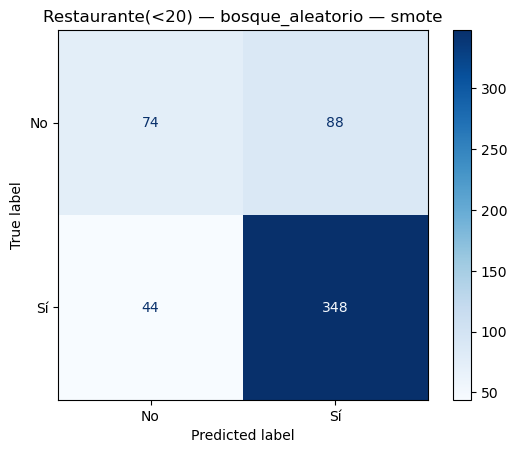

In [19]:
y_pred = mejor_modelo.predict(X_test)
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['No', 'Sí'], zero_division=0))
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['No', 'Sí'], cmap='Blues'
)
plt.title(f'{CUPON} — {ALGORITMO} — {variante_elegida}')
plt.show()


In [20]:
def metricas_modelo(y_true, y_pred):
    return {
        'precision_si': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'recall_si': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_si': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_minoritaria': recall_score(y_true, y_pred, pos_label=clase_minoritaria, zero_division=0),
    }

comparacion_train_test = pd.DataFrame({
    'train': metricas_modelo(y_train, mejor_modelo.predict(X_train)),
    'test': metricas_modelo(y_test, y_pred),
}).T
display(comparacion_train_test.round(3))


,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
train,0.899,0.947,0.923,0.859,0.744
test,0.798,0.888,0.841,0.685,0.457


In [21]:
pred_sin_balanceo = rf_grid.best_estimator_.predict(X_test)
resultados = pd.DataFrame([{
    'cupon': CUPON, 'algoritmo': ALGORITMO, 'variante': 'sin_balanceo',
    'elegida_por_cv': variante_elegida == 'sin_balanceo',
    'f1_macro_cv': rf_grid.best_score_, 'clase_minoritaria': clase_minoritaria,
    **metricas_modelo(y_test, pred_sin_balanceo),
}])


In [22]:
pred_smote = smote_grid.best_estimator_.predict(X_test)
fila_smote = pd.DataFrame([{
    'cupon': CUPON, 'algoritmo': ALGORITMO, 'variante': 'smote',
    'elegida_por_cv': variante_elegida == 'smote',
    'f1_macro_cv': smote_grid.best_score_, 'clase_minoritaria': clase_minoritaria,
    **metricas_modelo(y_test, pred_smote),
}])
resultados = pd.concat([resultados, fila_smote], ignore_index=True)


In [23]:
display(resultados.round(3))


,cupon,algoritmo,variante,elegida_por_cv,f1_macro_cv,clase_minoritaria,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
0,Restaurante(<20),bosque_aleatorio,sin_balanceo,False,0.668,0,0.779,0.944,0.854,0.663,0.352
1,Restaurante(<20),bosque_aleatorio,smote,True,0.694,0,0.798,0.888,0.841,0.685,0.457


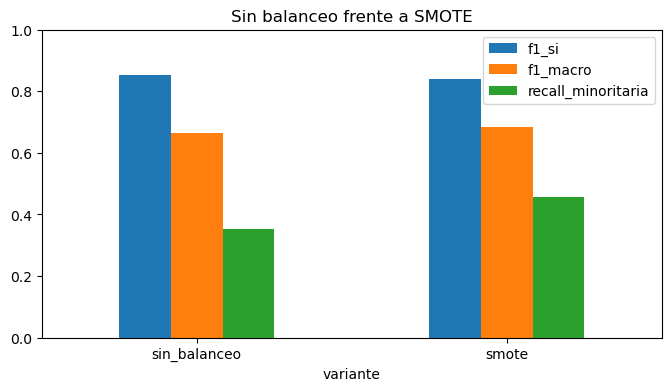

In [24]:
resultados.set_index('variante')[['f1_si', 'f1_macro', 'recall_minoritaria']].plot.bar(
    ylim=(0, 1), figsize=(8, 4), title='Sin balanceo frente a SMOTE'
)
plt.xticks(rotation=0)
plt.show()


**Por completar:** interpretar errores y brecha train–test. En Restaurante, comparar F1 de aceptación, F1 macro y recall minoritario y justificar si conviene SMOTE. En los datos originales la minoritaria de Restaurante es No; verificar después de limpiar. No cambiar la selección en función de test.


## 9. Interpretación del modelo

Seguimos el enfoque de la práctica: coeficientes para regresión, y reducción de impureza y reglas para árboles/bosques. Describen asociaciones del modelo, no relaciones causales.


In [25]:
preprocesador_fit = mejor_modelo.named_steps['preprocesador']
modelo_fit = mejor_modelo.named_steps['modelo']
feature_names = preprocesador_fit.get_feature_names_out()


cat__vigencia_cupon_2 horas                        0.069254
cat__vigencia_cupon_1 día                          0.066817
cat__hora_6:00 p.m.                                0.039584
cat__hora_10:00 p.m.                               0.031198
cat__destino_Sin lugar urgente                     0.029938
cat__hora_2:00 p.m.                                0.024755
cat__acompanante_Amigo(s)                          0.022821
cat__clima_Soleado                                 0.021463
cat__tiempo_cupon_mayor_25min_Sí                   0.016362
cat__tiempo_cupon_mayor_15min_No                   0.016112
cat__frecuencia_cafeteria_1 a 3                    0.016054
num__temperatura                                   0.015973
cat__acompanante_Solo                              0.015803
cat__frecuencia_cafeteria_nunca                    0.015731
cat__tiempo_cupon_mayor_25min_No                   0.015726
cat__frecuencia_comida_para_llevar_menos de 1      0.015442
cat__frecuencia_restaurante_menos_20_men

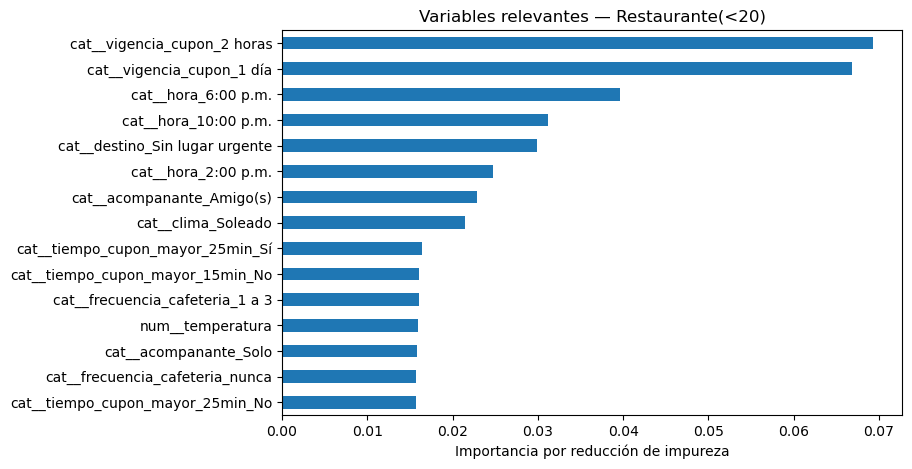

In [26]:
importancias = pd.Series(modelo_fit.feature_importances_, index=feature_names)
importancias = importancias.sort_values(ascending=False)
display(importancias.head(20))
importancias.head(15).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel('Importancia por reducción de impureza')
plt.title(f'Variables relevantes — {CUPON}')
plt.show()


Las importancias corresponden a columnas codificadas. Una variable original puede aparecer en varias categorías. La reducción de impureza puede favorecer variables con muchas categorías; considerar la correlación y evitar conclusiones causales. **Por completar:** identificar variables originales relevantes e indicar qué categorías aparecen.


## 10. Guardar resultados

Persistimos el pipeline, como en la práctica 7, y las métricas para integrar después. Este modelo se ajustó solo en train. El ganador de cada cupón se reajustará con todos sus datos etiquetados al generar el CSV externo.


In [27]:
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
resultados.to_csv(RUTA_RESULTADOS / 'metricas_test.csv', index=False, encoding='utf-8-sig')
resultados_cv.to_csv(RUTA_RESULTADOS / 'cv_sin_balanceo.csv', index=False, encoding='utf-8-sig')
particion = pd.concat([
    pd.DataFrame({'id_fila': X_train.index, 'conjunto': 'train'}),
    pd.DataFrame({'id_fila': X_test.index, 'conjunto': 'test'}),
], ignore_index=True)
particion.to_csv(RUTA_RESULTADOS / 'particion.csv', index=False)
pd.DataFrame({'id_fila': X_test.index, 'real': y_test.to_numpy(), 'prediccion': y_pred}).to_csv(
    RUTA_RESULTADOS / 'predicciones_test_interno.csv', index=False
)
joblib.dump(mejor_modelo, RUTA_RESULTADOS / 'pipeline_evaluado.joblib')


['resultados\\restaurante_bosque_aleatorio\\pipeline_evaluado.joblib']

In [28]:
pd.DataFrame(smote_grid.cv_results_).to_csv(
    RUTA_RESULTADOS / 'cv_smote.csv', index=False, encoding='utf-8-sig'
)


In [29]:
importancias.rename('importancia').to_csv(RUTA_RESULTADOS / 'importancias.csv', encoding='utf-8-sig')


## 11. Análisis para el informe conjunto

Completar después de ejecutar y contrastar los seis modelos:

- ¿Qué características se relacionan con la aceptación? ¿Cuáles parecen redundantes?
- ¿Cómo cambia el desempeño entre algoritmos y cupones? ¿Qué explicaría las diferencias?
- ¿Conviene el balanceo en Restaurante considerando F1 y recall minoritario?
- ¿Qué utilidad y limitación tienen las reglas o las importancias?
- ¿Cómo se integraría en la aplicación de conducción?
- ¿Qué limitaciones, fuentes de sesgo e implicaciones tiene usar edad, género, estado civil o ingreso? ¿Qué cambiaría en precios dinámicos?

El documento final debe responder las ocho preguntas del enunciado explícitamente, con evidencia propia.


## 12. Uso de herramientas de IA generativa

**Herramienta y propósito:** Codex (OpenAI), apoyo conceptual y generación/adaptación inicial de código a las prácticas 7–10 del curso. La plantilla se entrega sin resultados de entrenamiento del laboratorio.

**Prompts principales resumidos:**

1. Revisar el lab 3 de 202620, repartir los seis modelos entre dos integrantes y crear un notebook por modelo; dejar la limpieza al estudiante.
2. Revisar las prácticas y adaptar los notebooks a los métodos y la forma de trabajo del curso.

**Evaluación crítica del estudiante — completar al menos dos:** ¿qué fue útil y cómo se verificó?, ¿qué errores o limitaciones se identificaron?, ¿qué decisiones se cambiaron y por qué?, ¿qué conceptos del curso permitieron revisar la propuesta?

**Aportes propios — completar:** decisiones de limpieza, cambios al código, justificaciones, ejecución, interpretación y aprendizajes. Registrar los prompts adicionales que influyan en la entrega.
